# Data Analysis: Statistical Modelling and Inference

> **Who is this for:** a beginner who knows pandas and basic statistics (mean, standard deviation, a t-test) and wants to answer questions like *"how much does one more year of education raise wages, and how sure are we?"*. Also for BS/MS students in an "Advanced Statistics" or "Econometrics for Data Science" course, and for interviews where you are asked to read a regression table.
>
> **What you will learn:**
> - **prediction vs inference**: when the coefficients and their uncertainty matter more than the accuracy
> - **OLS with formulas** in `statsmodels` (`smf.ols`): reading every part of the summary (coefficients, standard errors, t, p, confidence intervals, R², F-test), categorical encoding and interactions, checked against a from-scratch implementation
> - **diagnostics** (residual plots, Q-Q plot, leverage and Cook's distance, VIF, Breusch–Pagan) and **fixes** (transformations, robust **HC3** and **clustered** standard errors)
> - **GLM inference**: logistic regression with odds ratios and marginal effects, Poisson regression with rate ratios
> - **nonparametric tests** (Mann–Whitney, Wilcoxon signed-rank, Kruskal–Wallis) and a **permutation test** from scratch
> - **sampling designs** (simple random, stratified, cluster, systematic), design weights and post-stratification, compared by simulation
> - **mixed / hierarchical models** for grouped data
> - **honest reporting**: effect sizes, confidence intervals, and a p-hacking simulation
>
> **Prerequisites:** [statistics](08_statistics.ipynb), [maths: statistics](../14_Mathematics/04_statistics.ipynb), [linear regression](../03_Machine_Learning/01_supervised/01_linear_regression.ipynb). Helpful: [generalized linear models](../03_Machine_Learning/01_supervised/08_generalized_linear_models.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, synthetic data with known true values (so you can check whether the methods find the truth).
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

A **statistical model** is a simple formula that describes how one thing changes with others, for example "wage goes up by about 8% for each extra year of school". **Inference** means asking *how sure* we are about such a number, because we only ever see a **sample** (some people), not everybody. So every estimate comes with a **margin of error**, written as a **confidence interval**: "8%, give or take 1%". The tricky part is that the margin of error is only right if the model's assumptions hold, so we also learn to **check** the model (like a doctor's check-up) and to **fix** it when needed. Finally, *how* you choose your sample matters as much as the maths: asking only your friends gives a very different answer from asking a random group.

**Everyday examples:**
- A pollster says "candidate A: 52% ± 3%". The 52% is the estimate, the ± 3% is the uncertainty. If the pollster only phoned landlines (mostly older people), the number can be wrong in a way that no ± can fix.
- A doctor checks whether a medicine lowers blood pressure. A good model says not only "it lowers it by 5 points" but also "between 3 and 7 points", and checks that the patients were not all from one hospital.

**Tiny example:** we measure 4 students: hours studied 1, 2, 3, 4 and test scores 52, 55, 61, 64. A straight line through these points rises by about **4.2 points per hour**. With only 4 students the margin of error is wide; with 400 students it would be much narrower.

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Regression coefficient + confidence interval | "how much Y changes per unit of X, give or take" | pricing studies, medical research, explaining model features |
| Diagnostics and robust standard errors | check the model's assumptions; widen the error bars when they fail | economics, A/B test analysis, ML model audits |
| Sampling design and weights | how the sample was chosen, and how to correct for it | election polls, census surveys, evaluating LLMs on a balanced test set |

### How this notebook is different from its neighbours

| Notebook | Focus |
|---|---|
| [08_statistics](08_statistics.ipynb), [14_Mathematics/04_statistics](../14_Mathematics/04_statistics.ipynb) | distributions, hypothesis tests, confidence intervals, bootstrap |
| [01_supervised/01_linear_regression](../03_Machine_Learning/01_supervised/01_linear_regression.ipynb) | regression as a **prediction** model (fit, regularisation, evaluation) |
| [01_supervised/08_generalized_linear_models](../03_Machine_Learning/01_supervised/08_generalized_linear_models.ipynb) | GLM families and link functions |
| **This notebook** | regression as an **inference** tool: standard errors, diagnostics, robust/clustered errors, sampling design, mixed models, reporting |

## 0. Setup

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import warnings
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.diagnostic import het_breuschpagan
print("statsmodels", statsmodels.__version__, "| scipy", scipy.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


statsmodels 0.14.6 | scipy 1.18.0


---
## 1. Prediction vs inference

> 💬 **In plain English:** decide first whether you want to guess new values (prediction) or understand and trust the effects (inference).

| | **Prediction** | **Inference** |
|---|---|---|
| Question | "What will Y be for this new case?" | "How does Y change with X, and how sure are we?" |
| What matters | out-of-sample error (RMSE, AUC) | coefficient, its **standard error**, confidence interval, assumptions |
| Typical models | gradient boosting, neural nets, anything that predicts well | linear/GLM/mixed models with interpretable parameters |
| Validation | train/test split, cross-validation | diagnostics, robustness checks, study design |
| Example | predict tomorrow's sales per store | estimate how much a 10% price cut changes sales |

They can disagree: a model can predict well while its coefficients are meaningless (e.g. two almost identical features share the effect randomly; see VIF in Section 3), and a model with low R² can still estimate an effect precisely. And even a precise coefficient is a **causal** effect only if the design supports it (randomisation, or the causal methods in [10_causal_inference](../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb)).

The **data** for Sections 2–3: 600 synthetic workers. Because we generate the data ourselves, we know the **true** coefficients and can check whether the confidence intervals contain them.

| Variable | Meaning | True effect on log(wage) |
|---|---|---|
| `educ` | years of education (10–18) | +0.08 per year in the private sector, +0.05 in the public sector |
| `exper` | years of experience (0–30) | +0.04 per year, with a diminishing return −0.0006 × exper² |
| `region` | North / South / East / West | South −0.10, East +0.05, West 0 (vs North) |
| `sector` | private / public | public +0.30 at educ = 0 (shifts the intercept) |
| `certified` | has a professional certificate (0/1) | +0.10 |

In [2]:
rng = np.random.default_rng(42)
n = 600
wages = pd.DataFrame({
    "educ": rng.integers(10, 19, n),
    "exper": rng.uniform(0, 30, n).round(1),
    "region": rng.choice(["North", "South", "East", "West"], n, p=[0.3, 0.3, 0.2, 0.2]),
    "sector": rng.choice(["private", "public"], n, p=[0.7, 0.3]),
    "certified": rng.binomial(1, 0.35, n),
})
region_eff = wages["region"].map({"North": 0.0, "South": -0.10, "East": 0.05, "West": 0.0})
public = (wages["sector"] == "public").astype(int)
log_wage = (1.5 + 0.08 * wages["educ"] + 0.04 * wages["exper"] - 0.0006 * wages["exper"] ** 2
            + region_eff + 0.30 * public - 0.03 * wages["educ"] * public + 0.10 * wages["certified"]
            + rng.normal(0, 0.30, n))
wages["wage"] = np.exp(log_wage).round(2)          # hourly wage in some currency; the log is the natural scale
print(wages.head())
print(wages.describe().round(2).loc[["mean", "std", "min", "max"]])

   educ  exper region   sector  certified   wage
0    10   23.4  South  private          1  15.36
1    16    4.0  North   public          0  18.67
2    15   16.1  North  private          1  26.10
3    13   15.4  South  private          1  15.22
4    13   25.7   West   public          0  16.36
       educ  exper  certified   wage
mean  14.01  15.04       0.35  22.42
std    2.61   8.74       0.48   9.61
min   10.00   0.00       0.00   5.28
max   18.00  30.00       1.00  70.09


---
## 2. OLS with formulas, and how to read the summary

> 💬 **In plain English:** fit a straight-line model with one formula string and learn to read every number in its report card.

**Ordinary least squares (OLS)** chooses the coefficients $\hat\beta$ that minimise the sum of squared residuals $\sum_i (y_i - x_i^\top\beta)^2$. In matrix form the solution is

$$\hat\beta = (X^\top X)^{-1} X^\top y, \qquad \widehat{\mathrm{Var}}(\hat\beta) = \hat\sigma^2 (X^\top X)^{-1}, \qquad \hat\sigma^2 = \frac{\sum_i e_i^2}{n - p}$$

where $p$ is the number of coefficients. The **standard error (SE)** of a coefficient is the square root of its diagonal entry: it measures how much $\hat\beta_j$ would vary across repeated samples. Then

- **t statistic** $= \hat\beta_j / \mathrm{SE}_j$: how many standard errors the estimate is away from 0,
- **p-value**: the probability of a |t| at least this large **if the true coefficient were 0** (and the assumptions hold),
- **95% confidence interval** $\hat\beta_j \pm t_{0.975,\,n-p}\cdot \mathrm{SE}_j$: a procedure that covers the true value in 95% of repeated samples.

The classic assumptions behind these formulas: (1) linearity in the parameters, (2) independent observations, (3) **homoskedasticity** (constant error variance), (4) no perfect multicollinearity, (5) for small samples, normally distributed errors.

**Formulas** (Patsy-style syntax, borrowed from R) describe the model in one string:

| Formula piece | Meaning |
|---|---|
| `y ~ x1 + x2` | intercept + two slopes (intercept is automatic; `- 1` removes it) |
| `np.log(wage)` | transform a variable inside the formula |
| `I(exper**2)` | arithmetic inside `I()` (otherwise `**` means interactions) |
| `C(region)` | treat as categorical: one dummy per level except a **reference** level |
| `C(region, Treatment("North"))` | choose the reference level explicitly |
| `a:b` | interaction only; `a * b` = `a + b + a:b` |

In [3]:
formula = ('np.log(wage) ~ educ * C(sector) + exper + I(exper**2) '
           '+ C(region, Treatment("North")) + certified')
ols = smf.ols(formula, data=wages).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:           np.log(wage)   R-squared:                       0.483
Model:                            OLS   Adj. R-squared:                  0.475
Method:                 Least Squares   F-statistic:                     61.24
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           9.35e-79
Time:                        14:45:59   Log-Likelihood:                -120.22
No. Observations:                 600   AIC:                             260.4
Df Residuals:                     590   BIC:                             304.4
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

### How to read this table (top to bottom)

| Part | What it says here | How to use it |
|---|---|---|
| `No. Observations`, `Df Residuals` | 600 rows, 600 − 10 coefficients = 590 | the $n - p$ in $\hat\sigma^2$ and in the t-distribution |
| `R-squared`, `Adj. R-squared` | share of variance of log(wage) explained; adjusted penalises extra terms | describes fit, **not** whether coefficients are right |
| `F-statistic`, `Prob (F-statistic)` | test that **all** slopes are 0 at once | almost always tiny; rarely the interesting question |
| `coef` | estimated effect on log(wage) per unit, holding the other terms fixed | interpret on the right scale (below) |
| `std err`, `t`, `P>|t|` | uncertainty, signal-to-noise, test of "coef = 0" | look at the SE and CI more than at the p-value |
| `[0.025 0.975]` | 95% confidence interval | the range of effects compatible with the data |
| `Omnibus`, `Jarque-Bera`, `Skew`, `Kurtosis` | tests and shape of the residual distribution | a quick normality check |
| `Durbin-Watson` | autocorrelation of residuals in **row order** (≈ 2 means none) | only meaningful if rows have an order (time) |
| `Cond. No.` | condition number of $X$; large values flag collinearity or unscaled variables | here large mainly because `exper**2` is in the hundreds |

**Reading the coefficients:**
- Log outcome: a coefficient $b$ means a change of $100\,(e^{b} - 1)\%$ in wage, about $100\,b\%$ when $b$ is small.
- `educ` is the education slope in the **reference** sector (private); `educ:C(sector)[T.public]` is how much **flatter or steeper** it is in the public sector. The public-sector slope is the sum of the two.
- `C(region, ...)[T.South]` compares South with the reference level North.

In [4]:
truth = pd.Series({
    "Intercept": 1.5, "C(sector)[T.public]": 0.30, "educ": 0.08, "educ:C(sector)[T.public]": -0.03,
    'C(region, Treatment("North"))[T.East]': 0.05, 'C(region, Treatment("North"))[T.South]': -0.10,
    'C(region, Treatment("North"))[T.West]': 0.0, "exper": 0.04, "I(exper ** 2)": -0.0006, "certified": 0.10})
ci = ols.conf_int()
table = pd.DataFrame({"true": truth, "estimate": ols.params, "SE": ols.bse,
                      "CI low": ci[0], "CI high": ci[1]}).loc[ols.params.index]
table["CI covers truth"] = (table["CI low"] <= table["true"]) & (table["true"] <= table["CI high"])
table["% change in wage"] = 100 * (np.exp(table["estimate"]) - 1)
print(table.round(4).to_string())
print(f"\nThe true value is inside {table['CI covers truth'].sum()} of {len(table)} intervals "
      "(we expect about 95% in the long run).")

b = ols.params
slope_public = b["educ"] + b["educ:C(sector)[T.public]"]
print(f"Return to one year of education: private {100*b['educ']:.1f}% vs public {100*slope_public:.1f}% (log points)")

                                          true  estimate      SE  CI low  CI high  CI covers truth  % change in wage
Intercept                               1.5000    1.4801  0.0928  1.2979   1.6622             True          339.3301
C(sector)[T.public]                     0.3000    0.3553  0.1437  0.0731   0.6374             True           42.6553
C(region, Treatment("North"))[T.East]   0.0500    0.0596  0.0371 -0.0134   0.1325             True            6.1387
C(region, Treatment("North"))[T.South] -0.1000   -0.1083  0.0314 -0.1700  -0.0466             True          -10.2680
C(region, Treatment("North"))[T.West]   0.0000   -0.0290  0.0344 -0.0966   0.0386             True           -2.8585
educ                                    0.0800    0.0811  0.0057  0.0699   0.0924             True            8.4490
educ:C(sector)[T.public]               -0.0300   -0.0335  0.0100 -0.0532  -0.0138             True           -3.2970
exper                                   0.0400    0.0389  0.0056

**What just happened?** The estimates are close to the true values, and the confidence intervals cover the truth for the coefficients (in repeated samples, about 1 in 20 intervals would miss it). The interaction lets the return to education differ by sector, exactly as the data were generated.

### 2.1 Checking statsmodels against a from-scratch OLS

A good habit: compute the core numbers yourself once, so the summary is no longer a black box. `ols.model.exog` is the design matrix $X$ that the formula created (with the dummy columns).

In [5]:
X = ols.model.exog                                   # n x p design matrix built from the formula
y = ols.model.endog                                  # log(wage)
n_obs, p = X.shape
XtX_inv = np.linalg.inv(X.T @ X)
beta = XtX_inv @ X.T @ y                             # normal equations (fine for small p; lstsq/QR is more stable)
resid = y - X @ beta
sigma2 = resid @ resid / (n_obs - p)                 # unbiased estimate of the error variance
se = np.sqrt(np.diag(sigma2 * XtX_inv))
t_stat = beta / se
p_val = 2 * stats.t.sf(np.abs(t_stat), df=n_obs - p)
r2 = 1 - resid @ resid / np.sum((y - y.mean()) ** 2)
print("design-matrix columns:", ols.model.exog_names)
assert np.allclose(beta, ols.params) and np.allclose(se, ols.bse) and np.allclose(p_val, ols.pvalues)
assert np.isclose(r2, ols.rsquared)
print(f"From scratch == statsmodels: coefficients, SEs, p-values and R² ({r2:.4f}) all match.")

design-matrix columns: ['Intercept', 'C(sector)[T.public]', 'C(region, Treatment("North"))[T.East]', 'C(region, Treatment("North"))[T.South]', 'C(region, Treatment("North"))[T.West]', 'educ', 'educ:C(sector)[T.public]', 'exper', 'I(exper ** 2)', 'certified']
From scratch == statsmodels: coefficients, SEs, p-values and R² (0.4830) all match.


### 2.2 Testing several coefficients at once: the F-test

"Does region matter at all?" is a question about **three** coefficients together (South, East, West vs North). Testing them one by one inflates the error rate and ignores their correlation. The **F-test** compares the full model with a **restricted** model without region:

$$F = \frac{(RSS_{restricted} - RSS_{full}) / q}{RSS_{full} / (n - p)} \sim F_{q,\,n-p} \text{ under } H_0$$

with $q$ = number of restrictions (here 3).

In [6]:
restricted = smf.ols('np.log(wage) ~ educ * C(sector) + exper + I(exper**2) + certified', data=wages).fit()
q = 3
F = ((restricted.ssr - ols.ssr) / q) / (ols.ssr / ols.df_resid)
p_F = stats.f.sf(F, q, ols.df_resid)
print(f"By hand: F = {F:.3f}, p = {p_F:.2e}")
print(sm.stats.anova_lm(restricted, ols))                              # same test, statsmodels
hyp = ", ".join(f'C(region, Treatment("North"))[T.{r}] = 0' for r in ["East", "South", "West"])
print(ols.f_test(hyp))                                                   # same test, written as hypotheses

By hand: F = 8.000, p = 3.11e-05
   df_resid        ssr  df_diff   ss_diff         F    Pr(>F)
0     593.0  54.578829      0.0       NaN       NaN       NaN
1     590.0  52.445542      3.0  2.133286  7.999657  0.000031
<F test: F=7.999656697552536, p=3.110619161139208e-05, df_denom=590, df_num=3>


> ⚠️ **Common mistake:** reading "p > 0.05" as "no effect". `West` vs North has a large p-value because its true effect **is** 0 here, but in general a large p-value can also mean "too little data to tell". Look at the confidence interval: a narrow interval around 0 is evidence of a small effect; a wide one is just uncertainty.
>
> 🎓 **Exam / interview tip:** "What does a 95% CI mean?" → If we repeated the study many times, 95% of the intervals computed this way would contain the true value. It is **not** "there is a 95% probability that the true value is in this particular interval" (that is the Bayesian *credible* interval's interpretation).

---
## 3. Diagnostics, and what to do when assumptions fail

> 💬 **In plain English:** give the model a health check, and widen its error bars when its assumptions are broken.

The SEs and p-values above are only right if the assumptions hold. **Diagnostics** check them using the residuals $e_i = y_i - \hat y_i$:

| Plot / statistic | Checks | Bad sign |
|---|---|---|
| Residuals vs fitted values | linearity, constant variance | curve (missed non-linearity), funnel (heteroskedasticity) |
| Normal **Q-Q plot** of residuals | normality of errors | points far off the line in the tails |
| **Leverage** $h_{ii}$ (diagonal of the hat matrix $X(X^\top X)^{-1}X^\top$) | unusual **x** values | $h_{ii} > 2p/n$ |
| **Cook's distance** $D_i$ | influence: how much all fitted values move if row $i$ is dropped | $D_i > 4/n$ (rule of thumb), or clearly separated from the rest |
| **VIF** (variance inflation factor) $= 1/(1 - R_j^2)$ | multicollinearity: $R_j^2$ from regressing $x_j$ on the other predictors | VIF > 5–10 |
| **Breusch–Pagan test** | heteroskedasticity: regresses $e^2$ on the predictors; LM $= nR^2 \sim \chi^2$ | small p-value |

To practise, we build a dataset with **three problems on purpose**: house prices where (a) the noise grows with the size of the house (heteroskedasticity), (b) two predictors measure almost the same thing (area in m² and number of rooms), and (c) one data-entry error (a mansion recorded at a tiny price).

In [7]:
rng = np.random.default_rng(8)
n = 300
area = rng.uniform(40, 250, n)                                     # m²
rooms = np.round(area / 30 + rng.normal(0, 0.4, n))                # almost determined by area -> collinear
age = rng.uniform(0, 60, n)                                        # years
price = (20 + 1.5 * area - 0.4 * age) * np.exp(rng.normal(0, 0.15, n))  # multiplicative noise: bigger houses, bigger errors
houses = pd.DataFrame({"price": price, "area": area, "rooms": rooms, "age": age})
houses.loc[0, ["area", "price"]] = [245.0, 30.0]                   # a data-entry error: big house, tiny price

m_house = smf.ols("price ~ area + rooms + age", data=houses).fit()
print(m_house.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     20.1968      6.616      3.053      0.002       7.176      33.218
area           1.0205      0.133      7.665      0.000       0.758       1.283
rooms         14.6071      3.891      3.754      0.000       6.949      22.265
age           -0.4856      0.134     -3.630      0.000      -0.749      -0.222


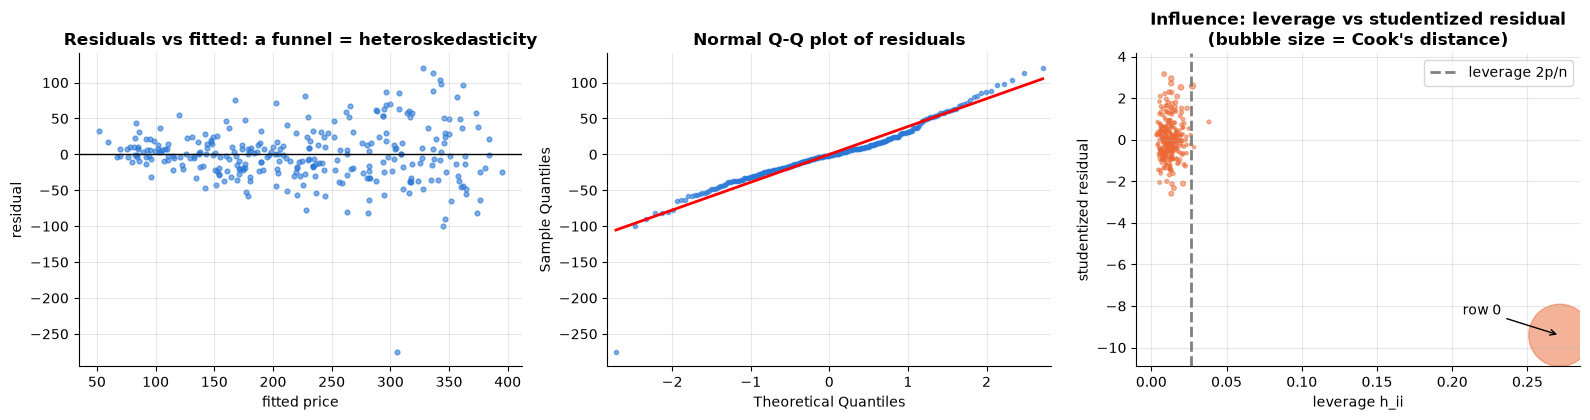

Row with the largest Cook's distance: 0 (D = 6.37, threshold 4/n = 0.013)
Rows above 4/n: 14


In [8]:
infl = OLSInfluence(m_house)
fitted, resid = m_house.fittedvalues, m_house.resid
lev, cooks = infl.hat_matrix_diag, infl.cooks_distance[0]
stud = infl.resid_studentized_external

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].scatter(fitted, resid, s=12, alpha=0.6)
axes[0].axhline(0, color="black", lw=1)
axes[0].set(title="Residuals vs fitted: a funnel = heteroskedasticity", xlabel="fitted price", ylabel="residual")
sm.qqplot(resid, line="s", ax=axes[1], markersize=3, alpha=0.6)
axes[1].set_title("Normal Q-Q plot of residuals")
sizes = 2000 * cooks / cooks.max() + 5
axes[2].scatter(lev, stud, s=sizes, alpha=0.5, color=PALETTE[1])
axes[2].axvline(2 * m_house.df_model / n + 2 / n, ls="--", color="grey", label="leverage 2p/n")
axes[2].set(title="Influence: leverage vs studentized residual\n(bubble size = Cook's distance)",
            xlabel="leverage h_ii", ylabel="studentized residual"); axes[2].legend()
worst = int(np.argmax(cooks))
axes[2].annotate(f"row {worst}", (lev[worst], stud[worst]), xytext=(-70, 15), textcoords="offset points",
                 arrowprops={"arrowstyle": "->"})
axes[2].set_ylim(stud.min() - 1.5, stud.max() + 1)
plt.tight_layout(); plt.show()

print(f"Row with the largest Cook's distance: {worst} (D = {cooks[worst]:.2f}, threshold 4/n = {4/n:.3f})")
print("Rows above 4/n:", int((cooks > 4 / n).sum()))

In [9]:
# VIF: one auxiliary regression per predictor (statsmodels does exactly this)
Xh = m_house.model.exog
vif = pd.Series([variance_inflation_factor(Xh, i) for i in range(1, Xh.shape[1])],
                index=m_house.model.exog_names[1:], name="VIF")
print(vif.round(1))
# By hand for 'rooms': R² of rooms ~ area + age
r2_rooms = smf.ols("rooms ~ area + age", data=houses).fit().rsquared
print(f"by hand: VIF(rooms) = 1 / (1 - {r2_rooms:.3f}) = {1 / (1 - r2_rooms):.1f}")

lm_stat, lm_p, f_stat, f_p = het_breuschpagan(m_house.resid, m_house.model.exog)
print(f"\nBreusch-Pagan: LM = {lm_stat:.1f}, p = {lm_p:.1e}  -> constant variance is clearly rejected")

area     12.4
rooms    12.4
age       1.0
Name: VIF, dtype: float64
by hand: VIF(rooms) = 1 / (1 - 0.920) = 12.4

Breusch-Pagan: LM = 78.7, p = 5.9e-17  -> constant variance is clearly rejected


**What just happened?** All three planted problems show up:
1. the residual plot is a **funnel** and Breusch–Pagan rejects constant variance,
2. `area` and `rooms` have high **VIFs** (their standard errors are inflated because the model cannot tell them apart),
3. row 0 stands out with by far the largest **Cook's distance**.

### Fixes
| Problem | Fix |
|---|---|
| Data error / influential point | check the raw record; correct or remove it **with a written reason**; never delete points just because they are inconvenient |
| Collinearity | drop or combine redundant predictors (keep `area`), or accept wide SEs if you only need predictions |
| Heteroskedasticity | transform the outcome (log often stabilises variance), or keep the model and use **heteroskedasticity-robust (HC) standard errors** |
| Non-linearity | add terms (`I(x**2)`, splines), or transform |

**Robust standard errors** keep the same coefficients but estimate their variance with the "sandwich" formula $(X^\top X)^{-1} X^\top \hat\Omega X (X^\top X)^{-1}$, where $\hat\Omega$ uses each observation's own squared residual instead of one common $\hat\sigma^2$. **HC3** divides each squared residual by $(1-h_{ii})^2$, which works best in small samples (MacKinnon & White 1985; Long & Ervin 2000).

In [10]:
fixed = houses.drop(index=0)                                            # documented: data-entry error in row 0
m_plain = smf.ols("price ~ area + age", data=fixed).fit()               # 'rooms' dropped (collinear)
m_hc3 = smf.ols("price ~ area + age", data=fixed).fit(cov_type="HC3")   # same coefficients, robust SEs
m_log = smf.ols("np.log(price) ~ np.log(area) + age", data=fixed).fit() # transformation alternative

cmp = pd.DataFrame({"coef": m_plain.params, "SE classic": m_plain.bse, "SE HC3": m_hc3.bse})
print(cmp.round(4))
for name, m in [("price ~ area + age", m_plain), ("log(price) ~ log(area) + age", m_log)]:
    print(f"Breusch-Pagan p for {name:30s}: {het_breuschpagan(m.resid, m.model.exog)[1]:.3g}")
print(f"\nElasticity from the log-log model: a 1% larger area -> {m_log.params['np.log(area)']:.2f}% higher price")

              coef  SE classic  SE HC3
Intercept  18.2292      5.8183  5.0989
area        1.5361      0.0339  0.0361
age        -0.5252      0.1175  0.1115
Breusch-Pagan p for price ~ area + age            : 8.6e-12
Breusch-Pagan p for log(price) ~ log(area) + age  : 0.905

Elasticity from the log-log model: a 1% larger area -> 0.95% higher price


**What just happened?** With HC3 the coefficients are identical but the SE of `area` grows, because the classic formula assumed equal noise everywhere and was too optimistic. The log-log model largely removes the funnel (Breusch–Pagan no longer rejects at 5%), and its coefficient is an **elasticity**.

### 3.1 Clustered standard errors

Robust (HC) SEs fix unequal variance but still assume **independent** rows. Often rows come in **clusters** that share unobserved shocks: students in the same school, purchases by the same customer, days in the same store. If the variable of interest is also constant within a cluster (a school-level programme, a store-level price change), the classic SE can be **far too small**.

**Cluster-robust SEs** sum the score contributions within each cluster before forming the sandwich, so they allow any correlation inside a cluster (they need a reasonable number of clusters, roughly 40+).

The simulation below checks **coverage**: in 200 repeated studies (40 stores × 25 days, the treatment assigned per store, store-level shocks), how often does each 95% CI contain the true effect?

In [11]:
def one_study(rng, G=40, m=25, beta=0.5, rho=0.3):
    g = np.repeat(np.arange(G), m)
    treat = np.repeat(rng.binomial(1, 0.5, G), m)                       # assigned per store
    shock = np.repeat(rng.normal(0, np.sqrt(rho), G), m)                # shared within a store
    y = 1 + beta * treat + shock + rng.normal(0, np.sqrt(1 - rho), G * m)
    d = pd.DataFrame({"y": y, "treat": treat, "store": g})
    mod = smf.ols("y ~ treat", data=d)
    out = {}
    for name, kw in [("classic", {}), ("HC3", {"cov_type": "HC3"}),
                     ("cluster", {"cov_type": "cluster", "cov_kwds": {"groups": d["store"]}})]:
        lo, hi = mod.fit(**kw).conf_int().loc["treat"]
        out[name] = lo <= beta <= hi
    return out

rng = np.random.default_rng(3)
cover = pd.DataFrame([one_study(rng) for _ in range(200)]).mean()
print("Share of 95% CIs that contain the true effect (200 simulated studies):")
print((100 * cover).round(1).astype(str) + " %")

Share of 95% CIs that contain the true effect (200 simulated studies):
classic    46.5 %
HC3        47.5 %
cluster    95.5 %
dtype: object


**What just happened?** With store-level shocks and a store-level treatment, the classic and HC3 intervals cover the truth far less often than the promised 95%: they are **overconfident** because 1,000 rows from 40 stores carry roughly the information of a much smaller sample. The cluster-robust interval is close to 95%. The size of the problem is the **design effect** $1 + (m - 1)\rho$ (here $1 + 24 \times 0.3 = 8.2$): the variance is about 8 times what the independent-rows formula assumes.

> 🎓 **Exam / interview tip:** "When do you cluster standard errors?" → At the level at which treatment is assigned or at which errors are correlated (users in an A/B test with many sessions per user, stores, schools, countries). With few clusters (< ~30–40) use small-sample corrections or a wild cluster bootstrap.

---
## 4. GLM inference: odds ratios, marginal effects, rate ratios

> 💬 **In plain English:** for yes/no and count outcomes, report effects as 'times more likely' or 'percentage points'.

When the outcome is binary (bought / did not buy) or a count (number of claims), linear regression is the wrong model. A **generalised linear model (GLM)** links the mean of $y$ to the linear predictor through a **link function** (see [08_generalized_linear_models](../03_Machine_Learning/01_supervised/08_generalized_linear_models.ipynb) for the theory). For inference the key question is: **on what scale do I report the coefficient?**

| Model | Link | $e^{\beta}$ is a... | Example sentence |
|---|---|---|---|
| Logistic (binary $y$) | logit $\log\frac{p}{1-p}$ | **odds ratio** | "a discount multiplies the odds of buying by 1.8" |
| Poisson (count $y$) | log | **rate ratio** | "young drivers have 1.6 times the claim rate per year insured" |

Odds ratios are hard for non-statisticians; the **average marginal effect (AME)** translates a logistic coefficient into **percentage points of probability**, averaged over the sample.

In [12]:
rng = np.random.default_rng(15)
n = 2000
shop = pd.DataFrame({"discount": rng.binomial(1, 0.5, n),
                     "visits": rng.poisson(3, n),
                     "device": rng.choice(["desktop", "mobile"], n, p=[0.4, 0.6])})
lin = -2.0 + 0.6 * shop["discount"] + 0.25 * shop["visits"] - 0.4 * (shop["device"] == "mobile")
shop["bought"] = rng.binomial(1, 1 / (1 + np.exp(-lin)))

logit = smf.logit("bought ~ discount + visits + C(device)", data=shop).fit(disp=0)
or_table = pd.DataFrame({"coef (log-odds)": logit.params, "odds ratio": np.exp(logit.params),
                         "OR 2.5%": np.exp(logit.conf_int()[0]), "OR 97.5%": np.exp(logit.conf_int()[1]),
                         "p": logit.pvalues})
print(or_table.round(3))
ame = logit.get_margeff(at="overall").summary_frame()               # average marginal effects
print("\nAverage marginal effects (change in purchase probability):")
print(ame.round(4))

                     coef (log-odds)  odds ratio  OR 2.5%  OR 97.5%    p
Intercept                     -1.944       0.143    0.109     0.188  0.0
C(device)[T.mobile]           -0.418       0.658    0.536     0.808  0.0
discount                       0.605       1.831    1.487     2.254  0.0
visits                         0.267       1.306    1.233     1.383  0.0

Average marginal effects (change in purchase probability):
                      dy/dx  Std. Err.       z  Pr(>|z|)  Conf. Int. Low  Cont. Int. Hi.
C(device)[T.mobile] -0.0769     0.0191 -4.0357    0.0001         -0.1142         -0.0395
discount             0.1112     0.0190  5.8436    0.0000          0.0739          0.1485
visits               0.0491     0.0050  9.7509    0.0000          0.0392          0.0589


In [13]:
# Poisson with exposure: claims counted over different lengths of insurance (years)
rng = np.random.default_rng(12)
n = 3000
ins = pd.DataFrame({"age_group": rng.choice(["18-25", "26-50", "51+"], n, p=[0.2, 0.55, 0.25]),
                    "city": rng.binomial(1, 0.5, n),
                    "years": rng.uniform(0.2, 3.0, n).round(2)})            # exposure: time at risk
rate = 0.10 * np.exp(0.47 * (ins["age_group"] == "18-25") - 0.22 * (ins["age_group"] == "51+")
                     + 0.30 * ins["city"])
ins["claims"] = rng.poisson(rate * ins["years"])

pois = smf.glm('claims ~ C(age_group, Treatment("26-50")) + city', data=ins,
               family=sm.families.Poisson(), offset=np.log(ins["years"])).fit()
rr = pd.DataFrame({"rate ratio": np.exp(pois.params), "RR 2.5%": np.exp(pois.conf_int()[0]),
                   "RR 97.5%": np.exp(pois.conf_int()[1])})
print(rr.round(3))
print(f"\nTrue rate ratios: 18-25 = {np.exp(0.47):.2f}, 51+ = {np.exp(-0.22):.2f}, city = {np.exp(0.30):.2f}")
print(f"Overdispersion check: Pearson chi2 / df = {pois.pearson_chi2 / pois.df_resid:.2f} (about 1 is fine for Poisson)")

                                           rate ratio  RR 2.5%  RR 97.5%
Intercept                                       0.093    0.080     0.108
C(age_group, Treatment("26-50"))[T.18-25]       1.432    1.182     1.736
C(age_group, Treatment("26-50"))[T.51+]         0.899    0.727     1.110
city                                            1.402    1.186     1.657

True rate ratios: 18-25 = 1.60, 51+ = 0.80, city = 1.35
Overdispersion check: Pearson chi2 / df = 0.93 (about 1 is fine for Poisson)


**What just happened?** The logistic model estimates that a discount multiplies the **odds** of buying by about 1.8 (the true value is $e^{0.6}\approx 1.82$, inside the CI). The AME turns that into percentage points of purchase probability (read the `dy/dx` row for `discount`), which is what a manager understands. The Poisson model used the **offset** $\log(\text{years})$, so it models claims **per year insured**; the CIs of its rate ratios contain the true values, and the dispersion ratio near 1 says the Poisson variance assumption is reasonable (if it were much larger than 1, use a negative binomial model or robust SEs).

> ⚠️ **Common mistake:** calling an odds ratio a "relative risk". With a baseline probability of 10%, an odds ratio of 1.8 corresponds to a probability of about 16.7%, a risk ratio of about 1.67. The two are only close when the outcome is rare.

---
## 5. Nonparametric tests and permutation tests

> 💬 **In plain English:** tests that work with ranks or shuffling, so outliers and skewed data cannot fool them.

**Nonparametric** (distribution-free) tests do not assume normal data. Most work on **ranks**: replace each value by its position in the sorted list, so outliers and skew matter much less.

| Situation | Parametric test | Nonparametric alternative | Null hypothesis (informally) |
|---|---|---|---|
| 2 independent groups | Welch t-test | **Mann–Whitney U** (Wilcoxon rank-sum) | a random value from group A is equally likely to be above or below one from B |
| 2 paired measurements (before/after) | paired t-test | **Wilcoxon signed-rank** | the paired differences are symmetric around 0 |
| k ≥ 3 independent groups | one-way ANOVA | **Kruskal–Wallis H** | all groups have the same distribution |
| any statistic, exchangeable data | — | **permutation test** | group labels do not matter |

**Mann–Whitney by hand:** pool both samples and rank them; let $R_1$ be the sum of ranks of sample 1. Then $U_1 = R_1 - \frac{n_1(n_1+1)}{2}$ counts how many (x, y) pairs have x > y (ties count ½). Under $H_0$, $U_1$ has mean $n_1 n_2 / 2$.

Worked example: A = [3, 8, 9], B = [1, 2, 7]. Pooled ranks: 1→1, 2→2, 3→3, 7→4, 8→5, 9→6. $R_A = 3 + 5 + 6 = 14$, $U_A = 14 - 6 = 8$ out of $3 \times 3 = 9$ pairs (only the pair (3, 7) has A < B).

In [14]:
def mann_whitney_u(x, y):
    """U statistic of sample x (number of pairs with x > y, ties = 1/2), via ranks."""
    pooled = np.concatenate([x, y])
    ranks = stats.rankdata(pooled)                 # average ranks for ties
    r1 = ranks[: len(x)].sum()
    return r1 - len(x) * (len(x) + 1) / 2

assert mann_whitney_u(np.array([3, 8, 9]), np.array([1, 2, 7])) == 8      # the worked example

rng = np.random.default_rng(6)
# Delivery times (minutes): skewed, with a few very late deliveries
old = rng.lognormal(3.4, 0.4, 40)
new = rng.lognormal(3.1, 0.4, 35)
new[:2] = [240, 300]                                                     # two disasters (outliers)

u_ours = mann_whitney_u(new, old)
mw = stats.mannwhitneyu(new, old, alternative="two-sided")
assert np.isclose(u_ours, mw.statistic)
brute = sum((a > b) + 0.5 * (a == b) for a in new for b in old)          # brute force over all pairs
assert np.isclose(u_ours, brute)
tt = stats.ttest_ind(new, old, equal_var=False)
print(f"means: old {old.mean():.1f}, new {new.mean():.1f} | medians: old {np.median(old):.1f}, new {np.median(new):.1f}")
print(f"Mann-Whitney U = {u_ours:.0f} of {len(new)*len(old)} pairs, p = {mw.pvalue:.4f}")
print(f"Welch t-test:  t = {tt.statistic:.2f}, p = {tt.pvalue:.4f}  (the two outliers inflate the variance)")
print(f"P(random new delivery is faster than random old one) = {1 - u_ours / (len(new) * len(old)):.2f}")

means: old 34.6, new 37.1 | medians: old 33.6, new 23.1
Mann-Whitney U = 368 of 1400 pairs, p = 0.0004
Welch t-test:  t = 0.24, p = 0.8143  (the two outliers inflate the variance)
P(random new delivery is faster than random old one) = 0.74


In [15]:
# Paired: the same 15 drivers before and after a routing app -> Wilcoxon signed-rank
before = rng.normal(32, 6, 15).round(1)
after = (before - rng.normal(2.5, 3, 15)).round(1)
w = stats.wilcoxon(after, before)
print(f"Wilcoxon signed-rank: W = {w.statistic:.0f}, p = {w.pvalue:.4f}; median change = {np.median(after - before):.1f} min")

# k groups: three warehouses -> Kruskal-Wallis
wh = [rng.lognormal(3.3, 0.4, 30), rng.lognormal(3.3, 0.4, 30), rng.lognormal(3.55, 0.4, 30)]
kw = stats.kruskal(*wh)
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.4f} (at least one warehouse differs)")

Wilcoxon signed-rank: W = 23, p = 0.0353; median change = -3.0 min
Kruskal-Wallis: H = 24.54, p = 0.0000 (at least one warehouse differs)


### 5.1 Permutation test from scratch

The most general idea in testing: **if the null hypothesis is true, the group labels are arbitrary**. So shuffle the labels many times, recompute the statistic each time, and see how extreme the observed value is among the shuffled ones. It works for *any* statistic (difference in means, medians, a ratio, an AUC) and needs only exchangeability.

$$p = \frac{1 + \#\{|T_{perm}| \ge |T_{obs}|\}}{1 + B}$$

(the "+1" counts the observed arrangement itself, so p is never exactly 0).

In [16]:
def permutation_test(x, y, stat=lambda a, b: np.mean(a) - np.mean(b), n_perm=9999, seed=0):
    """Two-sided permutation p-value for stat(x, y)."""
    rng = np.random.default_rng(seed)
    pooled = np.concatenate([x, y])
    observed = stat(x, y)
    count = 0
    for _ in range(n_perm):
        perm = rng.permutation(pooled)                       # shuffle labels
        if abs(stat(perm[: len(x)], perm[len(x):])) >= abs(observed):
            count += 1
    return observed, (1 + count) / (1 + n_perm)

diff_median = lambda a, b: np.median(a) - np.median(b)
obs, p_perm = permutation_test(new, old, stat=diff_median)
ref = stats.permutation_test((new, old), diff_median, n_resamples=9999, random_state=0, vectorized=False)
print(f"difference in medians = {obs:.2f} min | our p = {p_perm:.4f} | scipy p = {ref.pvalue:.4f}")
assert abs(p_perm - ref.pvalue) < 0.02                       # both are Monte Carlo estimates of the same p

difference in medians = -10.53 min | our p = 0.0012 | scipy p = 0.0004


**What just happened?** The typical new delivery is clearly faster (lower median), but the two disasters pull the **mean** of the new process above the old one and inflate its variance, so the t-test sees nothing. The rank-based Mann–Whitney test and the permutation test on medians still detect that the new process is usually faster. Our from-scratch U equals scipy's and the brute-force pair count; our permutation p-value agrees with scipy's up to Monte Carlo noise.

> ⚠️ **Common mistake:** saying "Mann–Whitney compares medians". It compares whole distributions (precisely: $P(X > Y)$ vs ½). It is a test of medians only if the two distributions have the same shape.

---
## 6. Sampling design: how the sample was drawn changes the maths

> 💬 **In plain English:** how you pick the people you measure changes how sure you can be, and weights can correct some biases.

All formulas so far assumed a **simple random sample (SRS)**: every unit has the same chance and units are drawn independently. Real surveys rarely do that.

| Design | How | Why use it | Effect on precision |
|---|---|---|---|
| **Simple random** | draw n units at random | baseline | SE ≈ $\sqrt{(1 - n/N)\, s^2/n}$ |
| **Stratified** | split the population into strata (regions), draw an SRS in each | guarantee coverage of every group; precision | usually **better** than SRS when strata differ |
| **Cluster** | draw whole groups (villages, schools), measure everyone inside | cheaper fieldwork (travel to few places) | usually **worse**: design effect $1 + (m-1)\rho$ |
| **Systematic** | random start, then every k-th unit of a list | easy in practice | like SRS if the list order is unrelated to y; dangerous with periodic lists |

**Design weights.** If unit $i$ had probability $\pi_i$ of being selected, it "represents" $w_i = 1/\pi_i$ population units. The weighted (**Horvitz–Thompson / Hájek**) mean $\sum w_i y_i / \sum w_i$ is unbiased even when some groups were **oversampled** on purpose.

Our population: 20,000 households in 200 villages (100 each) and 4 regions; income depends on the region and on the village, so households in the same village are similar. The **intra-class correlation** $\rho$ (ICC) measures how similar: the share of the total variance that lies between villages. Each design draws **n = 400** households; the cluster design visits 20 villages and interviews 20 households in each (two-stage sampling).

In [17]:
rng = np.random.default_rng(2026)
N_VILL, PER_VILL = 200, 100
region_of_village = np.repeat(["A", "B", "C", "D"], [80, 60, 40, 20])                 # region sizes differ
region_mean = {"A": 30, "B": 40, "C": 55, "D": 80}                                     # income in thousands
village_eff = rng.normal(0, 6, N_VILL)
pop = pd.DataFrame({"village": np.repeat(np.arange(N_VILL), PER_VILL),
                    "region": np.repeat(region_of_village, PER_VILL)})
pop["income"] = (pop["region"].map(region_mean) + village_eff[pop["village"]]
                 + rng.normal(0, 12, len(pop))).clip(lower=1)
N = len(pop); TRUE_MEAN = pop["income"].mean()
# Intra-class correlation (ANOVA estimator): share of the total variance that lies BETWEEN villages
vm = pop.groupby("village")["income"]
icc = (vm.mean().var() - vm.var().mean() / PER_VILL) / pop["income"].var()
print(f"N = {N:,} households | true mean income = {TRUE_MEAN:.2f}k | intra-class correlation (villages) = {icc:.2f}")
print(pop.groupby("region")["income"].agg(["size", "mean"]).round(1))

N = 20,000 households | true mean income = 43.46k | intra-class correlation (villages) = 0.66
        size  mean
region            
A       8000  30.8
B       6000  39.6
C       4000  56.3
D       2000  80.3


In [18]:
n = 400
strata_sizes = pop["region"].value_counts().sort_index()
alloc = (n * strata_sizes / N).round().astype(int)                     # proportional allocation
idx_by_region = {r: g.index.to_numpy() for r, g in pop.groupby("region")}
inc = pop["income"].to_numpy()
pop_sorted = pop.sort_values(["region", "village"]).index.to_numpy()  # list ordered by region (implicit stratification)

def srs(rng):
    return inc[rng.choice(N, n, replace=False)].mean()

def stratified(rng):
    parts = [inc[rng.choice(idx_by_region[r], alloc[r], replace=False)] for r in alloc.index]
    return sum(strata_sizes[r] / N * p.mean() for r, p in zip(alloc.index, parts))   # weight strata by size

M_PER = 20                                                             # households interviewed per village
def cluster(rng):
    vills = rng.choice(N_VILL, n // M_PER, replace=False)              # stage 1: 20 villages
    hh = vills[:, None] * PER_VILL + np.array([rng.choice(PER_VILL, M_PER, replace=False) for _ in vills])
    return inc[hh.ravel()].mean()                                      # stage 2: 20 households in each

def systematic(rng):
    k = N // n
    start = rng.integers(k)
    return inc[pop_sorted[start::k][:n]].mean()

rng = np.random.default_rng(1)
REPS = 1000
est = pd.DataFrame({name: [f(rng) for _ in range(REPS)]
                    for name, f in [("simple random", srs), ("stratified (proportional)", stratified),
                                    ("cluster (20 villages x 20)", cluster), ("systematic (sorted list)", systematic)]})
summary = pd.DataFrame({"mean of estimates": est.mean(), "bias": est.mean() - TRUE_MEAN, "empirical SE": est.std()})
summary["SE relative to SRS"] = summary["empirical SE"] / summary.loc["simple random", "empirical SE"]
s2 = inc.var(ddof=1)
print(summary.round(3))
print(f"\nSRS formula SE = sqrt((1 - n/N) s²/n) = {np.sqrt((1 - n / N) * s2 / n):.3f}")
print(f"Cluster design effect predicted 1 + (m-1)·ICC = {1 + (M_PER - 1) * icc:.1f}  "
      f"(observed variance ratio = {summary.loc['cluster (20 villages x 20)', 'SE relative to SRS'] ** 2:.1f})")

                            mean of estimates   bias  empirical SE  SE relative to SRS
simple random                          43.414 -0.049         1.052               1.000
stratified (proportional)              43.459 -0.004         0.665               0.632
cluster (20 villages x 20)             43.458 -0.006         3.538               3.363
systematic (sorted list)               43.473  0.010         0.666               0.633

SRS formula SE = sqrt((1 - n/N) s²/n) = 1.018
Cluster design effect predicted 1 + (m-1)·ICC = 13.6  (observed variance ratio = 11.3)


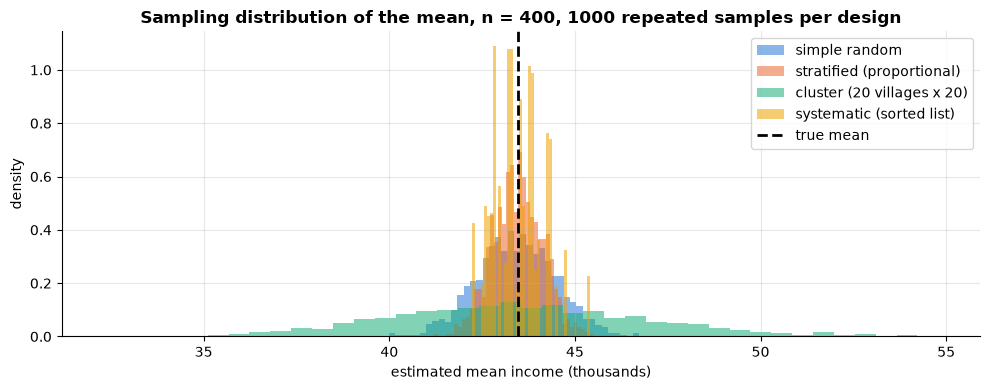

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, col in enumerate(est.columns):
    ax.hist(est[col], bins=40, alpha=0.55, label=col, color=PALETTE[i], density=True)
ax.axvline(TRUE_MEAN, color="black", ls="--", label="true mean")
ax.set(title=f"Sampling distribution of the mean, n = {n}, {REPS} repeated samples per design",
       xlabel="estimated mean income (thousands)", ylabel="density")
ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** All four designs are unbiased (the bias column is near 0), but their precision differs a lot. **Stratification** beats SRS because the regions really differ in income, so fixing how many households come from each region removes that source of variation. **Cluster sampling** is much worse: 400 households from only 20 villages contain far less information than 400 independent households, and the observed variance ratio is close to the design effect $1 + (m-1)\rho$ printed above. Field teams accept this loss because visiting 20 villages is much cheaper than visiting 400 scattered households. **Systematic** sampling from a list sorted by region behaves like implicit stratification. (Its histogram is spiky because with $k = N/n = 50$ there are only 50 possible systematic samples, one per random start.)

### 6.1 Oversampling and design weights; non-response and post-stratification

Region D is small (10% of households) but the government wants precise numbers for it, so the survey **oversamples** it: 100 households per region regardless of size. The naive mean then over-represents rich region D; the weighted mean fixes it.

**Post-stratification** fixes a different problem: **non-response**. Suppose richer households answer less often. If we know the true population share of each region (from a census), we re-weight respondents so each region gets its true share: $w = \frac{\text{population share}}{\text{sample share}}$.

In [20]:
rng = np.random.default_rng(9)
# (a) disproportionate stratified design: 100 per region
samp = pd.concat([pop.loc[rng.choice(idx_by_region[r], 100, replace=False)] for r in "ABCD"])
samp["pi"] = 100 / samp["region"].map(strata_sizes)                      # inclusion probability per region
samp["w"] = 1 / samp["pi"]                                                # design weight
naive = samp["income"].mean()
weighted = np.average(samp["income"], weights=samp["w"])
print(f"(a) oversampled region D | naive mean = {naive:.2f} | design-weighted mean = {weighted:.2f} | truth = {TRUE_MEAN:.2f}")

# (b) SRS of 2,000 households, but response probability falls with income
draw = pop.loc[rng.choice(N, 2000, replace=False)].copy()
p_resp = 1 / (1 + np.exp(-(1.5 - 0.035 * draw["income"])))               # rich households answer less
resp = draw[rng.random(len(draw)) < p_resp].copy()
pop_share = pop["region"].value_counts(normalize=True)
samp_share = resp["region"].value_counts(normalize=True)
resp["w_ps"] = resp["region"].map(pop_share / samp_share)                 # post-stratification weight
print(f"(b) {len(resp)} of 2000 responded | naive mean = {resp['income'].mean():.2f} | "
      f"post-stratified mean = {np.average(resp['income'], weights=resp['w_ps']):.2f} | truth = {TRUE_MEAN:.2f}")
print(pd.DataFrame({"population share": pop_share, "respondent share": samp_share}).round(3))

(a) oversampled region D | naive mean = 52.14 | design-weighted mean = 43.43 | truth = 43.46
(b) 984 of 2000 responded | naive mean = 36.86 | post-stratified mean = 40.20 | truth = 43.46
        population share  respondent share
region                                    
A                    0.4             0.489
B                    0.3             0.313
C                    0.2             0.155
D                    0.1             0.043


**What just happened?** (a) The naive mean of the oversampled design is pulled up by region D; the design weights restore the population mean. (b) Non-response makes the respondents poorer than the population, so the naive mean is too low. Post-stratifying by region removes the part of that bias that runs **between** regions; the part **within** regions (rich households in every region answering less) remains, so the weighted estimate is closer to the truth but still somewhat low. Weighting only fixes biases related to the variables you weight on: this is why pollsters weight on several variables (age, education, region, past vote; "raking").

> 🎓 **Exam / interview tip:** "Your survey's respondents are 70% women, the population is 50%. What do you do?" → post-stratify (or rake) to known population margins, report the **effective sample size** $(\sum w)^2/\sum w^2$ (weights cost precision), and admit that weighting cannot fix biases on unmeasured variables.

---
## 7. Mixed (hierarchical) models for grouped data

> 💬 **In plain English:** when data come in groups (schools, stores), model the groups so you do not pretend to have more information than you do.

When data are grouped (students in schools, measurements per patient, sessions per user), a **mixed model** adds a **random effect** for each group: every school gets its own intercept $u_j \sim N(0, \sigma_u^2)$ in addition to the **fixed effects** that are the same for everyone:

$$\text{score}_{ij} = \beta_0 + \beta_1\,\text{hours}_{ij} + \beta_2\,\text{funding}_j + u_j + \varepsilon_{ij}$$

What this buys you:
- correct SEs for **group-level** predictors (`funding` is constant within a school),
- the **intra-class correlation** ICC $= \sigma_u^2 / (\sigma_u^2 + \sigma_\varepsilon^2)$: how similar members of a group are,
- **partial pooling (shrinkage)**: a school's estimated effect is pulled towards the overall mean, more strongly when the school has few students. This is the same idea as regularisation in ML.

In [21]:
rng = np.random.default_rng(28)
S = 30
sizes = rng.integers(5, 40, S)                                     # unbalanced: some small schools
school = np.repeat(np.arange(S), sizes)
funding = np.repeat(rng.normal(0, 1, S), sizes)                   # school-level predictor (standardised)
u = rng.normal(0, 5, S)
hours = rng.uniform(0, 10, len(school))
score = 50 + 2.0 * hours + 3.0 * funding + u[school] + rng.normal(0, 8, len(school))
edu = pd.DataFrame({"score": score, "hours": hours, "funding": funding, "school": school})

mixed = smf.mixedlm("score ~ hours + funding", edu, groups=edu["school"]).fit(reml=True)
naive = smf.ols("score ~ hours + funding", edu).fit()
print(mixed.summary().tables[1])
var_u, var_e = float(mixed.cov_re.iloc[0, 0]), mixed.scale
print(f"ICC = {var_u:.1f} / ({var_u:.1f} + {var_e:.1f}) = {var_u / (var_u + var_e):.2f}")
print(pd.DataFrame({"OLS SE (ignores schools)": naive.bse, "mixed-model SE": mixed.bse[naive.bse.index]}).round(3))

            Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept  51.570    1.050  49.129  0.000  49.512  53.627
hours       1.867    0.101  18.511  0.000   1.669   2.065
funding     2.809    0.887   3.168  0.002   1.071   4.548
Group Var  21.505    0.856                               
ICC = 21.5 / (21.5 + 60.2) = 0.26
           OLS SE (ignores schools)  mixed-model SE
Intercept                     0.692           1.050
hours                         0.116           0.101
funding                       0.327           0.887


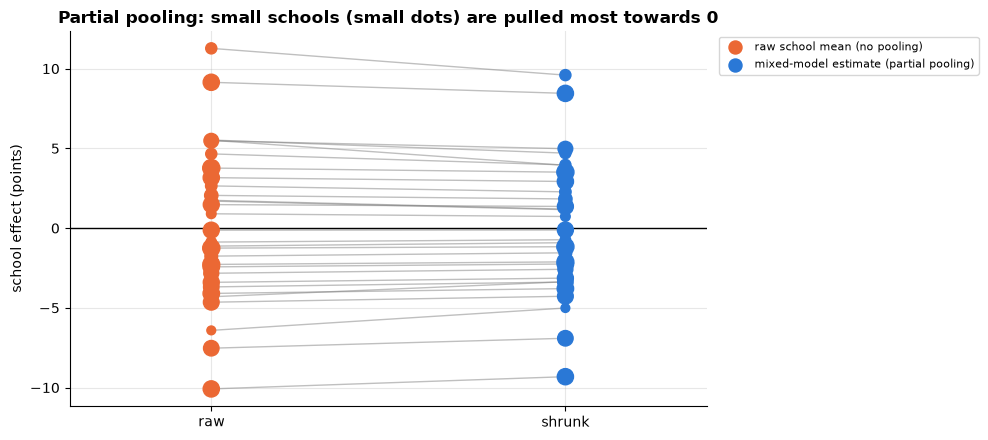

Correlation between school size and amount of shrinkage: -0.93 (negative = big schools shrink less)


In [22]:
# Shrinkage: raw school means of the residual vs the model's random-intercept predictions (BLUPs)
re = pd.Series({k: v.iloc[0] for k, v in mixed.random_effects.items()})
raw = (edu.assign(r=edu["score"] - mixed.fe_params["Intercept"] - mixed.fe_params["hours"] * edu["hours"]
                  - mixed.fe_params["funding"] * edu["funding"]).groupby("school")["r"].mean())
fig, ax = plt.subplots(figsize=(10, 4.5))
for s in range(S):
    ax.plot([0, 1], [raw[s], re[s]], color="grey", alpha=0.5, lw=1)
sc = ax.scatter(np.zeros(S), raw, s=sizes * 4, color=PALETTE[1], label="raw school mean (no pooling)", zorder=3)
ax.scatter(np.ones(S), re, s=sizes * 4, color=PALETTE[0], label="mixed-model estimate (partial pooling)", zorder=3)
ax.axhline(0, color="black", lw=1)
ax.set(xticks=[0, 1], xticklabels=["raw", "shrunk"], xlim=(-0.4, 1.4), ylabel="school effect (points)",
       title="Partial pooling: small schools (small dots) are pulled most towards 0")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8); plt.tight_layout(); plt.show()
shrink = (1 - re / raw).abs()
print(f"Correlation between school size and amount of shrinkage: {np.corrcoef(sizes, shrink)[0, 1]:.2f} (negative = big schools shrink less)")

**What just happened?** The fixed effects are close to the truth (hours 2.0, funding 3.0). Ordinary OLS treats every student as independent and reports a much smaller SE for the **school-level** `funding` effect than the mixed model: it pretends to have hundreds of independent schools when there are only 30. The shrinkage plot shows partial pooling: small schools' noisy raw means are pulled strongly towards the average; large schools barely move.

> ⚠️ **Common mistake:** using a random effect for a grouping variable with very few levels (e.g. 3 regions). The variance $\sigma_u^2$ cannot be estimated from 3 groups; use fixed effects (dummies) instead.

---
## 8. Honest reporting: effect sizes, intervals, and p-hacking

> 💬 **In plain English:** say how big an effect is and how uncertain, and do not keep trying analyses until one says 'significant'.

A **p-value** answers a narrow question: *how surprising would data like these be if there were no effect?* It does **not** tell you how big or important the effect is. The American Statistical Association's 2016 statement on p-values lists the key points:
1. p-values do not measure the probability that the hypothesis is true,
2. scientific conclusions should not rest only on whether p passes 0.05,
3. a p-value does not measure the size or importance of an effect,
4. proper inference requires full reporting and transparency.

So report an **effect size** with a **confidence interval**: a difference in means with its CI, an odds ratio with its CI, or a standardised effect such as **Cohen's d** $= (\bar x_1 - \bar x_2)/s_{pooled}$ (rough guide: 0.2 small, 0.5 medium, 0.8 large).

In [23]:
def cohens_d(a, b):
    na, nb_ = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb_ - 1) * b.var(ddof=1)) / (na + nb_ - 2))
    return (a.mean() - b.mean()) / sp

rng = np.random.default_rng(8)
huge_a, huge_b = rng.normal(100.3, 15, 100_000), rng.normal(100.0, 15, 100_000)   # tiny effect, huge n
small_a, small_b = rng.normal(108, 15, 12), rng.normal(100, 15, 12)               # bigger effect, tiny n
for label, a, b in [("huge sample, tiny effect", huge_a, huge_b), ("tiny sample, medium effect", small_a, small_b)]:
    t = stats.ttest_ind(a, b, equal_var=False)
    ci = t.confidence_interval()
    print(f"{label:28s} diff = {a.mean() - b.mean():6.2f} (95% CI {ci.low:6.2f} to {ci.high:6.2f}) "
          f"| d = {cohens_d(a, b):.2f} | p = {t.pvalue:.2g}")

huge sample, tiny effect     diff =   0.29 (95% CI   0.16 to   0.42) | d = 0.02 | p = 1.6e-05
tiny sample, medium effect   diff =  12.65 (95% CI  -1.50 to  26.79) | d = 0.76 | p = 0.077


**What just happened?** With 100,000 per group, a difference of a fraction of a point is "highly significant" yet practically negligible (d ≈ 0.02). With 12 per group, a large difference is "not significant" but the CI is wide: the honest summary is "we don't know yet", not "no effect". The CI tells both stories; the p-value alone tells neither.

### 8.1 A p-hacking simulation

**p-hacking** means trying many analyses and reporting the one with p < 0.05. Even with **no real effect**, this produces "discoveries". Two common forms:
- **many outcomes**: test 20 metrics, report whichever is significant. With independent tests, $P(\text{at least one } p<0.05) = 1 - 0.95^{20} \approx 0.64$.
- **optional stopping ("peeking")**: check the p-value after every batch of users and stop as soon as it is below 0.05.

In [24]:
rng = np.random.default_rng(0)
SIMS = 2000

# (a) 20 independent outcomes, no true effect anywhere: all simulations at once (vectorised t-tests)
a, b = rng.normal(size=(SIMS, 20, 30)), rng.normal(size=(SIMS, 20, 30))     # sims x 20 metrics x 30 users/group
p = stats.ttest_ind(a, b, axis=2).pvalue                                     # shape (SIMS, 20)
print(f"(a) 20 outcomes, no effect: 'found' something in {100 * (p < 0.05).any(axis=1).mean():.1f}% of studies "
      f"(theory {100 * (1 - 0.95 ** 20):.1f}%)")

# (b) optional stopping: look after every 10 users per group, up to 200; stop at the first p < 0.05
a, b = rng.normal(size=(SIMS, 200)), rng.normal(size=(SIMS, 200))
looks = np.arange(10, 201, 10)
p_at_look = np.column_stack([stats.ttest_ind(a[:, :k], b[:, :k], axis=1).pvalue for k in looks])
peeking_fp = (p_at_look < 0.05).any(axis=1).mean()                  # significant at ANY look
fixed_fp = (p_at_look[:, -1] < 0.05).mean()                         # only the planned final test
print(f"(b) peeking 20 times: false-positive rate {100 * peeking_fp:.1f}% vs {100 * fixed_fp:.1f}% with one test at n = 200")

(a) 20 outcomes, no effect: 'found' something in 64.2% of studies (theory 64.2%)


(b) peeking 20 times: false-positive rate 24.9% vs 4.5% with one test at n = 200


**What just happened?** With no real effect at all, testing 20 outcomes "finds" an effect in roughly 64% of studies, and peeking 20 times pushes the false-positive rate from 5% to several times that. Defences: **pre-register** the primary outcome and analysis plan, **correct for multiple testing** (Bonferroni, Holm, Benjamini–Hochberg; see [14_Mathematics/04_statistics](../14_Mathematics/04_statistics.ipynb)), use **sequential designs** that account for peeking (see [11_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb)), and report **all** analyses that were run.

### Common misinterpretations (exam favourites)

| Statement | Correct? | Why |
|---|---|---|
| "p = 0.03 means a 3% chance the null hypothesis is true" | ❌ | p is computed **assuming** the null is true |
| "p = 0.20, so there is no effect" | ❌ | absence of evidence ≠ evidence of absence; look at the CI |
| "p < 0.001, so the effect is large" | ❌ | p mixes effect size and sample size |
| "The 95% CI [2, 8] contains the true value with 95% probability" | ❌ (frequentist) | 95% is a property of the procedure over repeated samples |
| "Two results, one significant and one not, are significantly different from each other" | ❌ | test the difference directly |
| "R² = 0.15, so the model is useless for inference" | ❌ | a coefficient can be precise even when much variance is unexplained |

---
## 9. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same tools judge whether one AI model really beats another and whether an AI feature helped users.

- **Model evaluation is inference.** "Model B beats model A by 1.2 points on a 500-question benchmark" needs a CI and a paired test (questions are shared by both models); see [24_Research_Methods/03](../24_Research_Methods/03_statistical_significance_and_reporting.ipynb). Questions drawn from the same source document are **clusters**, so LLM-evaluation papers increasingly report clustered SEs.
- **A/B tests of ML features** ([11_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb)) are regressions with robust or user-clustered SEs, and suffer from peeking exactly as in Section 8.1.
- **Explaining models**: coefficients with CIs from a GLM are often the "glass-box" baseline that SHAP explanations of a boosted model ([07_explainability](../03_Machine_Learning/07_explainability/)) are compared against.
- **Mixed models and shrinkage** are the statistical ancestor of hierarchical Bayesian models ([14_Mathematics/07_bayesian_ml](../14_Mathematics/07_bayesian_ml.ipynb)) and of regularisation in ML.
- **Sampling design** matters for building training and evaluation sets: stratified sampling for rare classes, and weights to correct a test set that does not match production traffic.
- **Causal claims** need more than a regression; see [10_causal_inference](../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb).

## Recap

- **Inference** is about coefficients and their uncertainty; **prediction** is about out-of-sample error. Choose the tool for the question.
- `smf.ols("y ~ x + C(cat) + a*b", data)`; read coef, SE, CI first, p-values second; interpret log outcomes as % changes; the F-test checks groups of coefficients.
- Diagnose with residual-vs-fitted, Q-Q, leverage/Cook's distance, VIF and Breusch–Pagan. Fix with data checks, transformations, **HC3** SEs for heteroskedasticity and **clustered** SEs for grouped data.
- Report GLMs as **odds ratios** / **rate ratios** with CIs, and as **average marginal effects** for non-specialists.
- Rank-based tests (Mann–Whitney, Wilcoxon, Kruskal–Wallis) and **permutation tests** are robust alternatives when normality is doubtful.
- Sampling design changes the SE: stratification helps, clustering hurts (design effect $1+(m-1)\rho$); use **design weights**, and **post-stratification** for non-response.
- **Mixed models** handle grouped data, give correct SEs for group-level predictors, and shrink noisy group estimates.
- Report **effect sizes with CIs**; beware multiple outcomes and peeking (p-hacking).

## Practice problems

**1. (Easy, conceptual)** In `np.log(price) ~ sqm + garden`, the coefficient of `garden` (0/1) is 0.18 with 95% CI [0.10, 0.26]. Interpret it in one sentence a manager understands.

<details><summary>Show solution</summary>

Holding size fixed, houses with a garden sell for about $100(e^{0.18}-1) \approx 19.7\%$ more, and the data are compatible with roughly $10.5\%$ to $29.7\%$ ($e^{0.10}-1$ to $e^{0.26}-1$). This is an association; it is the causal effect of a garden only if nothing else that differs between houses with and without gardens (and affects price) is left out of the model.

</details>

**2. (Medium, coding)** Write `vif_by_hand(X)` that computes the VIF of each column of a predictor matrix by running the auxiliary regressions with `np.linalg.lstsq`, and check it against `variance_inflation_factor`.

<details><summary>Show solution</summary>

```python
import numpy as np

def vif_by_hand(X):
    """X: 2-D array of predictors (no intercept column). Returns the VIF of each column."""
    n, k = X.shape
    out = []
    for j in range(k):
        others = np.column_stack([np.ones(n), np.delete(X, j, axis=1)])   # intercept + other predictors
        coef, *_ = np.linalg.lstsq(others, X[:, j], rcond=None)
        resid = X[:, j] - others @ coef
        r2 = 1 - resid @ resid / np.sum((X[:, j] - X[:, j].mean()) ** 2)
        out.append(1 / (1 - r2))
    return np.array(out)

rng = np.random.default_rng(0)
a = rng.normal(size=500); b = a + rng.normal(scale=0.3, size=500); c = rng.normal(size=500)
print(vif_by_hand(np.column_stack([a, b, c])).round(2))
```
`b` is almost a copy of `a`, so both get large VIFs; `c` is independent and has a VIF near 1. Note: `variance_inflation_factor` must be given a design matrix **with** an intercept column, otherwise its numbers are wrong for uncentred data.

</details>

**3. (Easy, conceptual)** Which test would you use? (a) reaction times of the same 20 people with and without caffeine, heavily skewed; (b) customer ratings (1–5 stars) for 4 app versions, different customers per version; (c) conversion yes/no for two web designs with 10,000 users each.

<details><summary>Show solution</summary>

(a) **Wilcoxon signed-rank** (paired, non-normal), or a sign-flip permutation test. (b) **Kruskal–Wallis** (k independent groups, ordinal data), followed by pairwise Mann–Whitney tests with a multiple-testing correction. (c) A **two-proportion z-test** or chi-squared test (or logistic regression); with this sample size the normal approximation is excellent; report the difference in conversion rates with its CI.

</details>

**4. (Medium, coding)** Implement a **paired** permutation test by randomly flipping the signs of the paired differences, for `before = [31, 28, 35, 40, 29, 33, 37, 30, 34, 36]` and `after = [29, 27, 31, 37, 30, 30, 33, 28, 31, 35]`.

<details><summary>Show solution</summary>

```python
import numpy as np

def paired_permutation_test(before, after, n_perm=9999, seed=0):
    """Two-sided sign-flip permutation test for the mean paired difference."""
    rng = np.random.default_rng(seed)
    d = np.asarray(after) - np.asarray(before)
    obs = d.mean()
    signs = rng.choice([-1, 1], size=(n_perm, len(d)))        # under H0 each difference is equally likely +/-
    perm_means = (signs * d).mean(axis=1)
    return obs, (1 + np.sum(np.abs(perm_means) >= abs(obs))) / (1 + n_perm)

before = np.array([31, 28, 35, 40, 29, 33, 37, 30, 34, 36])
after = np.array([29, 27, 31, 37, 30, 30, 33, 28, 31, 35])
print(paired_permutation_test(before, after))
```
Under $H_0$ (no effect), each difference is equally likely to be positive or negative, so flipping signs generates the null distribution. The mean change is −2.2 and p < 0.01.

</details>

**5. (Easy, coding)** A school survey samples 40 classes and tests all 30 students in each (1,200 students). The intra-class correlation of test scores is 0.05. Compute the design effect and the effective sample size.

<details><summary>Show solution</summary>

```python
def design_effect(m, icc):
    return 1 + (m - 1) * icc

def effective_n(n, m, icc):
    return n / design_effect(m, icc)

n, m, icc = 1200, 30, 0.05            # 40 classes x 30 students
print(f"deff = {design_effect(m, icc):.2f}, effective sample size = {effective_n(n, m, icc):.0f}")
```
Even a small ICC of 0.05 cuts the information to that of about 490 independent students, because each class contributes 30 correlated answers.

</details>

**6. (Medium, coding)** Write `cohens_d_bootstrap_ci(a, b)` returning Cohen's d and a 95% percentile-bootstrap CI (resample each group with replacement).

<details><summary>Show solution</summary>

```python
import numpy as np

def cohens_d_bootstrap_ci(a, b, n_boot=4000, seed=0, level=0.95):
    rng = np.random.default_rng(seed)
    def d(x, y):
        sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
        return (x.mean() - y.mean()) / sp
    boots = [d(rng.choice(a, len(a)), rng.choice(b, len(b))) for _ in range(n_boot)]
    lo, hi = np.percentile(boots, [50 * (1 - level), 50 * (1 + level)])
    return d(a, b), lo, hi

rng = np.random.default_rng(1)
print(np.round(cohens_d_bootstrap_ci(rng.normal(0.5, 1, 80), rng.normal(0, 1, 80)), 3))
```

</details>

**7. (Hard, conceptual)** A colleague estimates the effect of a store-level price change on daily sales with OLS on 2 years × 50 stores of daily data and reports HC3 standard errors and p < 0.001. What is wrong, and how would you fix it?

<details><summary>Show solution</summary>

HC3 handles unequal variance but assumes **independent** rows. Daily sales of the same store are correlated (store-level shocks, autocorrelation over days), and the treatment varies at the **store** level, so the effective sample size is closer to 50 stores than to 36,500 rows; the SEs are far too small. Fixes: **cluster the SEs by store** (50 clusters is acceptable; with fewer use a wild cluster bootstrap), add store and date fixed effects (a difference-in-differences design if the change happened at different times), or aggregate to store-level before/after means. Also check for other changes happening at the same time in the treated stores (confounding).

</details>

**8. (Hard, conceptual)** Why does a random-intercept model shrink the estimate of a school with 5 students more than one with 40 students? Give the formula.

<details><summary>Show solution</summary>

For a random-intercept model the predicted school effect (BLUP) is the raw school mean deviation multiplied by a **reliability** factor
$\lambda_j = \dfrac{\sigma_u^2}{\sigma_u^2 + \sigma_\varepsilon^2 / n_j}$.
With few students ($n_j$ small) the raw mean is noisy ($\sigma_\varepsilon^2/n_j$ is large), so $\lambda_j$ is small and the estimate is pulled strongly towards the overall mean; with many students $\lambda_j \to 1$. It is a precision-weighted compromise between "each school on its own" (no pooling) and "all schools identical" (complete pooling), exactly like ridge regularisation or a Bayesian prior.

</details>

## Further reading

- J. M. Wooldridge, *Introductory Econometrics: A Modern Approach*, 7th ed., Ch. 3–4 (OLS inference), Ch. 8 (heteroskedasticity, robust SEs).
- A. Gelman, J. Hill & A. Vehtari, *Regression and Other Stories* (2020), and Gelman & Hill (2007) for multilevel models; free PDF of *Regression and Other Stories* on the authors' site.
- S. Lohr, *Sampling: Design and Analysis*, 3rd ed. (2021): stratified and cluster sampling, weights.
- A. C. Cameron & D. L. Miller (2015), "A Practitioner's Guide to Cluster-Robust Inference", *Journal of Human Resources* 50(2).
- R. Wasserstein & N. Lazar (2016), "The ASA Statement on p-Values: Context, Process, and Purpose", *The American Statistician* 70(2).
- Free: the [statsmodels documentation](https://www.statsmodels.org/stable/) (examples for OLS, GLM, MixedLM, robust covariance).

## Next notebook

➡️ [14_design_of_experiments.ipynb](14_design_of_experiments.ipynb): instead of analysing data you were given, **design** the data collection so that the answer is clear (randomisation, blocking, factorial designs, power).